# Tugas Praktikum: Klasifikasi Ensemble untuk Deteksi Fraud pada Data Tidak Seimbang

**Nama:** Firdaus Mangkona
**NIM:** 5054251003
**Mata Kuliah:** Data Mining
**Topik:** Ensemble Method & Penanganan Class Imbalance

---

## Deskripsi

Dataset yang digunakan adalah **Credit Card Fraud Detection** (Kaggle / ULB Machine Learning Group) yang memuat
transaksi kartu kredit oleh pemegang kartu Eropa pada September 2013. Dataset ini adalah contoh klasik
permasalahan **class imbalance ekstrem**: transaksi fraud hanya mencakup sebagian sangat kecil dari seluruh data.

Kolom dataset:

| Kolom | Keterangan |
|---|---|
| `Time` | Detik sejak transaksi pertama pada dataset |
| `V1` – `V28` | Komponen utama hasil **PCA** (fitur asli dirahasiakan untuk alasan kerahasiaan) |
| `Amount` | Nominal transaksi |
| `Class` | Target: `0` = transaksi normal, `1` = transaksi fraud |

## Daftar Isi

1. [Unduh dan Import Dataset](#1-unduh-dan-import-dataset)
2. [Praproses Data](#2-praproses-data)
3. [Membangun Model Klasifikasi](#3-membangun-model-klasifikasi)
4. [Evaluasi Model](#4-evaluasi-model)
5. [Kesimpulan](#5-kesimpulan)

## 1. Unduh dan Import Dataset

Dataset diunduh dari Kaggle: **Credit Card Fraud Detection**
(`https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud`) dan disimpan pada `data/creditcard.csv`.
Selanjutnya dataset dibaca dengan `pandas.read_csv()`.

In [1]:
import json
import time
import warnings
from pathlib import Path

import imblearn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score,
                            classification_report, confusion_matrix, f1_score,
                            precision_recall_curve, precision_score, recall_score,
                            roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- konfigurasi
RANDOM_STATE = 42          # seed tetap agar hasil dapat direproduksi
TEST_SIZE = 0.20           # pembagian data latih : data uji = 80 : 20
DATA_PATH = Path("data/creditcard.csv")
FIG_DIR = Path("figures")
RES_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

WARNA_KELAS = {0: "#4C72B0", 1: "#C44E52"}
LABEL_KELAS = {0: "Normal (0)", 1: "Fraud (1)"}

print(f"pandas         : {pd.__version__}")
print(f"numpy          : {np.__version__}")
print(f"scikit-learn   : {sklearn.__version__}")
print(f"imbalanced-learn: {imblearn.__version__}")

pandas         : 3.0.6
numpy          : 2.5.4
scikit-learn   : 1.9.1
imbalanced-learn: 0.14.2


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan pada '{DATA_PATH}'.\n"
        "Silakan unduh 'creditcard.csv' dari Kaggle (Credit Card Fraud Detection) "
        "lalu letakkan pada folder 'data/'."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset berhasil dimuat dari  : {DATA_PATH}")
print(f"Ukuran berkas                 : {DATA_PATH.stat().st_size / 1024**2:.1f} MB")

Dataset berhasil dimuat dari  : data/creditcard.csv
Ukuran berkas                 : 143.8 MB


### 1.1 Struktur Data — `.head()`

Menampilkan 5 baris pertama untuk memastikan data terbaca dengan benar dan melihat rentang nilai setiap kolom.

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### 1.2 Dimensi dan Tipe Data — `.shape` dan `.info()`

In [4]:
print(f"Jumlah baris (transaksi) : {df.shape[0]:,}")
print(f"Jumlah kolom (fitur)     : {df.shape[1]}")
print("\n=== df.info() ===")
df.info()

Jumlah baris (transaksi) : 284,807
Jumlah kolom (fitur)     : 31

=== df.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     28480

In [5]:
pemeriksaan = pd.DataFrame({
    "tipe_data": df.dtypes.astype(str),
    "nilai_kosong": df.isna().sum(),
    "jumlah_unik": df.nunique(),
    "min": df.min().round(2),
    "max": df.max().round(2),
})
pemeriksaan

,tipe_data,nilai_kosong,jumlah_unik,min,max
Time,float64,0,124592,0.00,172792.00
V1,float64,0,275663,-56.41,2.45
V2,float64,0,275663,-72.72,22.06
V3,float64,0,275663,-48.33,9.38
V4,float64,0,275663,-5.68,16.88
V5,float64,0,275663,-113.74,34.80
V6,float64,0,275663,-26.16,73.30
V7,float64,0,275663,-43.56,120.59
V8,float64,0,275663,-73.22,20.01
V9,float64,0,275663,-13.43,15.59


In [6]:
print(f"Nilai kosong (missing value) total : {int(df.isna().sum().sum())}")
print(f"Baris duplikat                     : {int(df.duplicated().sum())}")
print(f"Kolom 'Class' unik                 : {sorted(df['Class'].unique().tolist())}")

Nilai kosong (missing value) total : 0
Baris duplikat                     : 1081
Kolom 'Class' unik                 : [0, 1]


**Interpretasi struktur data**

* Dataset memuat **284.807 transaksi** dengan **31 kolom**: 28 komponen PCA (`V1`–`V28`), `Time`, `Amount`, dan target `Class`.
* Seluruh kolom bertipe numerik (`float64`/`int64`) dan **tidak ada missing value** sehingga tidak diperlukan imputasi.
* `V1`–`V28` sudah merupakan hasil PCA sehingga **bebas multikolinearitas** dan sudah terskala.
  Kolom `Time` dan `Amount` masih dalam skala asli, sehingga keduanya perlu distandardisasi pada tahap praproses
  (penting agar perhitungan jarak Euclidean oleh SMOTE tidak didominasi oleh nominal `Amount`).

## 2. Praproses Data

### 2.1 Identifikasi Distribusi Kelas

Langkah pertama praproses adalah mengukur ketidakseimbangan kelas target `Class`
dalam bentuk **jumlah** dan **persentase**.

In [7]:
jumlah_kelas = df["Class"].value_counts().sort_index()
persentase_kelas = df["Class"].value_counts(normalize=True).sort_index() * 100

tabel_distribusi = pd.DataFrame({
    "Kelas": [LABEL_KELAS[i] for i in jumlah_kelas.index],
    "Jumlah Transaksi": jumlah_kelas.to_numpy(),
    "Persentase (%)": persentase_kelas.round(4).to_numpy(),
}).set_index("Kelas")

rasio_imbalance = jumlah_kelas[0] / jumlah_kelas[1]
print(f"Rasio ketidakseimbangan : 1 transaksi fraud berbanding {rasio_imbalance:,.0f} transaksi normal")
print(f"Kelas minoritas (fraud)  : {jumlah_kelas[1]:,} dari {len(df):,} baris")
tabel_distribusi

Rasio ketidakseimbangan : 1 transaksi fraud berbanding 578 transaksi normal
Kelas minoritas (fraud)  : 492 dari 284,807 baris


,Jumlah Transaksi,Persentase (%)
Kelas,,
Normal (0),284315,99.8273
Fraud (1),492,0.1727


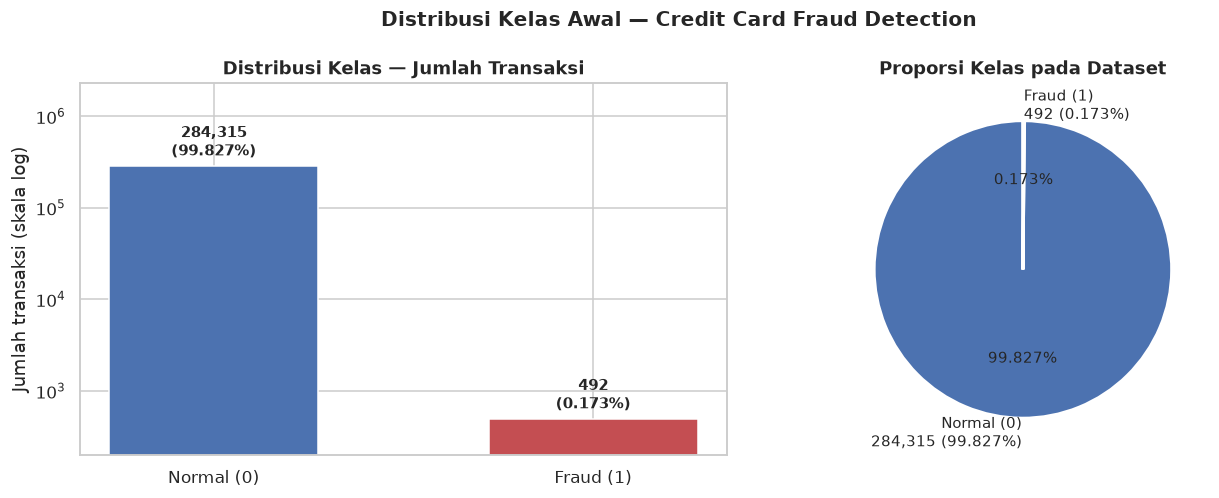

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

# --- panel 1: jumlah transaksi per kelas (skala log agar batang fraud tetap terlihat)
batang = axes[0].bar(
    [LABEL_KELAS[i] for i in jumlah_kelas.index],
    jumlah_kelas.to_numpy(),
    color=[WARNA_KELAS[i] for i in jumlah_kelas.index],
    width=0.55,
)
axes[0].set_yscale("log")
axes[0].set_ylim(jumlah_kelas.min() * 0.4, jumlah_kelas.max() * 8)  # ruang untuk label nilai
axes[0].set_ylabel("Jumlah transaksi (skala log)")
axes[0].set_title("Distribusi Kelas — Jumlah Transaksi")
for b, nilai, pct in zip(batang, jumlah_kelas.to_numpy(), persentase_kelas.to_numpy()):
    axes[0].text(b.get_x() + b.get_width() / 2, nilai * 1.15, f"{nilai:,}\n({pct:.3f}%)",
                 ha="center", va="bottom", fontsize=10, fontweight="bold")

# --- panel 2: proporsi kelas
axes[1].pie(
    jumlah_kelas.to_numpy(),
    labels=[f"{LABEL_KELAS[i]}\n{p:,} ({pct:.3f}%)" for i, p, pct in
            zip(jumlah_kelas.index, jumlah_kelas.to_numpy(), persentase_kelas.to_numpy())],
    colors=[WARNA_KELAS[i] for i in jumlah_kelas.index],
    autopct="%1.3f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10},
)
axes[1].set_title("Proporsi Kelas pada Dataset")

fig.suptitle("Distribusi Kelas Awal — Credit Card Fraud Detection", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribusi_kelas.png")
plt.show()

### 2.2 Eksplorasi Karakteristik Nominal dan Waktu Transaksi

Sebelum pemodelan, perlu dipahami apakah transaksi fraud memiliki pola nominal (`Amount`) dan waktu (`Time`)
yang berbeda dari transaksi normal.

In [9]:
statistik_amount = df.groupby("Class")["Amount"].agg(["count", "mean", "median", "std", "max"]).round(2)
statistik_amount.index = [LABEL_KELAS[i] for i in statistik_amount.index]
statistik_amount

,count,mean,median,std,max
Normal (0),284315,88.29,22.00,250.11,25691.16
Fraud (1),492,122.21,9.25,256.68,2125.87


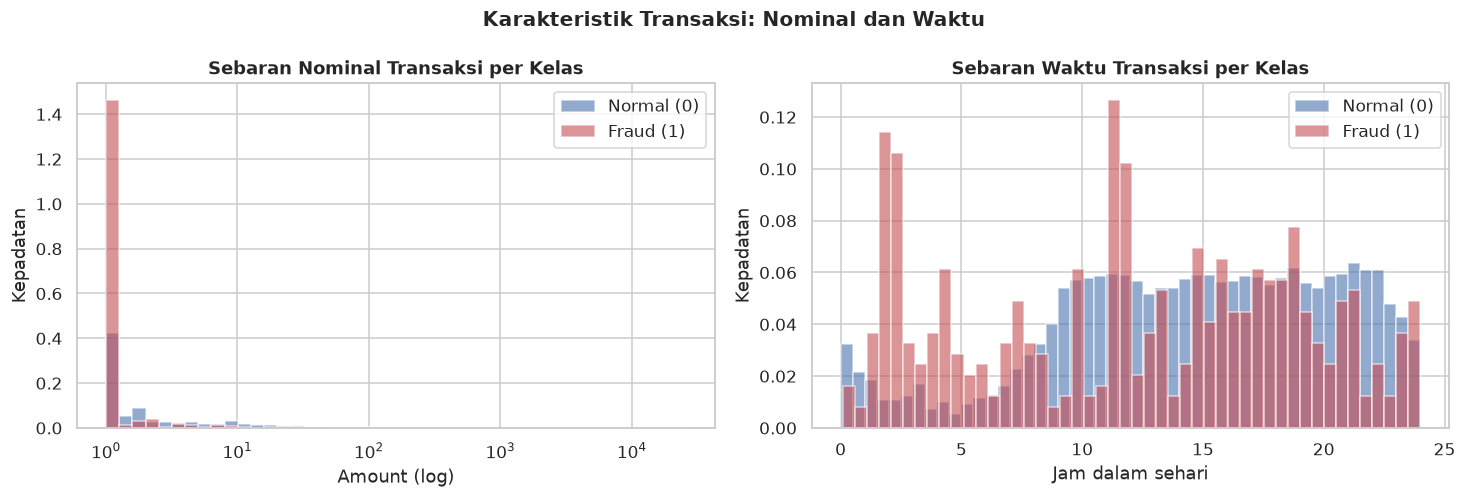

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# --- panel 1: distribusi Amount per kelas (sumbu-x log)
for kelas in (0, 1):
    nilai = df.loc[df["Class"] == kelas, "Amount"]
    bins = np.logspace(0, np.log10(df["Amount"].max() + 1), 45)
    axes[0].hist(np.clip(nilai, 1, None), bins=bins, density=True, alpha=0.6,
                 color=WARNA_KELAS[kelas], label=LABEL_KELAS[kelas])
axes[0].set_xscale("log")
axes[0].set_xlabel("Amount (log)")
axes[0].set_ylabel("Kepadatan")
axes[0].set_title("Sebaran Nominal Transaksi per Kelas")
axes[0].legend()

# --- panel 2: distribusi jam transaksi per kelas
for kelas in (0, 1):
    jam = (df.loc[df["Class"] == kelas, "Time"] / 3600) % 24
    axes[1].hist(jam, bins=48, density=True, alpha=0.6, color=WARNA_KELAS[kelas],
                 label=LABEL_KELAS[kelas])
axes[1].set_xlabel("Jam dalam sehari")
axes[1].set_ylabel("Kepadatan")
axes[1].set_title("Sebaran Waktu Transaksi per Kelas")
axes[1].legend()

fig.suptitle("Karakteristik Transaksi: Nominal dan Waktu", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_amount_dan_waktu_per_kelas.png")
plt.show()

### 2.3 Pembagian Data Latih dan Data Uji (80 : 20, `stratify=y`)

Data dibagi **sebelum** resampling agar tidak terjadi *data leakage*: data uji merepresentasikan
kondisi nyata (distribusi asli yang tidak seimbang) dan tidak boleh mengandung sampel sintetis.
Parameter `stratify=y` menjaga proporsi kelas tetap sama pada kedua bagian.

In [11]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,          # proporsi fraud dijaga identik pada data latih dan data uji
)

tabel_split = pd.DataFrame({
    "Data Latih (80%)": [int((y_train == 0).sum()), int((y_train == 1).sum()), len(y_train)],
    "Data Uji (20%)": [int((y_test == 0).sum()), int((y_test == 1).sum()), len(y_test)],
}, index=["Normal (0)", "Fraud (1)", "Total"])
tabel_split["% Fraud"] = [
    (y_train == 1).mean() * 100, (y_test == 1).mean() * 100, y.mean() * 100
]
tabel_split["% Fraud"] = tabel_split["% Fraud"].round(4)
tabel_split

,Data Latih (80%),Data Uji (20%),% Fraud
Normal (0),227451,56864,0.1729
Fraud (1),394,98,0.1720
Total,227845,56962,0.1727


In [12]:
# verifikasi: pembagian stratifikasi harus mempertahankan proporsi kelas pada kedua subset
selisih_proporsi = abs((y_train == 1).mean() - (y_test == 1).mean())
assert selisih_proporsi < 1e-4, "Proporsi kelas data latih dan data uji berbeda terlalu jauh"
assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(set(X_test.index))
print(f"Selisih proporsi fraud latih vs uji : {selisih_proporsi:.2e}  -> stratifikasi berhasil")
print(f"Data uji tetap memakai distribusi asli ({int(y_test.sum())} fraud dari {len(y_test):,} transaksi)")

Selisih proporsi fraud latih vs uji : 8.80e-06  -> stratifikasi berhasil
Data uji tetap memakai distribusi asli (98 fraud dari 56,962 transaksi)


### 2.4 Standardisasi `Time` dan `Amount`

`V1`–`V28` sudah terskala karena merupakan keluaran PCA. Sebaliknya `Time` (ratusan ribu detik) dan
`Amount` (hingga ribuan) masih berskala besar. Keduanya distandardisasi dengan `StandardScaler`
yang **di-fit hanya pada data latih** untuk mencegah kebocoran informasi dari data uji.

Standardisasi ini krusial untuk SMOTE: algoritma tersebut membangkitkan sampel sintetis berdasarkan
**jarak antar tetangga terdekat (k-NN)**, sehingga tanpa standardisasi jarak akan didominasi
oleh kolom `Amount`.

In [13]:
KOLOM_DISKALAKAN = ["Time", "Amount"]

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[KOLOM_DISKALAKAN] = scaler.fit_transform(X_train[KOLOM_DISKALAKAN])
X_test[KOLOM_DISKALAKAN] = scaler.transform(X_test[KOLOM_DISKALAKAN])

print("Statistik setelah standardisasi (data latih):")
print(X_train[KOLOM_DISKALAKAN].describe().loc[["mean", "std", "min", "max"]].round(4))

Statistik setelah standardisasi (data latih):
        Time    Amount
mean -0.0000    0.0000
std   1.0000    1.0000
min  -1.9981   -0.3517
max   1.6405  102.1170


### 2.5 Penanganan Class Imbalance

Diterapkan **dua pendekatan resampling** yang hanya dikenakan pada data latih:

1. **SMOTE (Synthetic Minority Over-sampling Technique)** — membangkitkan sampel fraud sintetis
   dengan interpolasi linier antar tetangga terdekat pada ruang fitur, sehingga kelas minoritas
   menjadi seimbang **tanpa menduplikasi data** (berbeda dari *random oversampling*).
2. **Random Undersampling** — mengurangi jumlah transaksi normal secara acak hingga setara
   dengan jumlah transaksi fraud (hanya ~788 baris latih yang tersisa).

Data uji **tidak disentuh** oleh kedua metode tersebut.

In [14]:
# --- 1) SMOTE: oversampling kelas minoritas pada data latih
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# --- 2) Random undersampling kelas mayoritas pada data latih
undersampler = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_under, y_train_under = undersampler.fit_resample(X_train, y_train)

tabel_resampling = pd.DataFrame({
    "Data Latih (asli)": [len(y_train) - int(y_train.sum()), int(y_train.sum()), len(y_train)],
    "Data Latih + SMOTE": [len(y_train_smote) - int(y_train_smote.sum()), int(y_train_smote.sum()), len(y_train_smote)],
    "Data Latih + Undersampling": [len(y_train_under) - int(y_train_under.sum()), int(y_train_under.sum()), len(y_train_under)],
    "Data Uji (asli)": [len(y_test) - int(y_test.sum()), int(y_test.sum()), len(y_test)],
}, index=["Normal (0)", "Fraud (1)", "Total"])

tabel_resampling.loc["% Fraud"] = (
    tabel_resampling.loc["Fraud (1)"] / tabel_resampling.loc["Total"] * 100
).round(2)
tabel_resampling

,Data Latih (asli),Data Latih + SMOTE,Data Latih + Undersampling,Data Uji (asli)
Normal (0),227451.00,227451.0,394.0,56864.00
Fraud (1),394.00,227451.0,394.0,98.00
Total,227845.00,454902.0,788.0,56962.00
% Fraud,0.17,50.0,50.0,0.17


In [15]:
# verifikasi: hasil resampling seimbang dan data uji sama sekali tidak diubah
assert int(y_train_smote.sum()) == len(y_train_smote) - int(y_train_smote.sum()), "SMOTE tidak menghasilkan kelas seimbang"
assert int(y_train_under.sum()) == len(y_train_under) - int(y_train_under.sum()), "Undersampling tidak menghasilkan kelas seimbang"
assert len(X_test) == len(y_test)
assert abs(len(y_test) / len(df) - TEST_SIZE) < 0.005, "Pembagian data tidak sesuai proporsi 80:20"
assert list(X_train_under.columns) == list(X_train.columns)
print(f"Baris latih setelah SMOTE           : {len(y_train_smote):,}")
print(f"Baris latih setelah undersampling   : {len(y_train_under):,}")
print(f"Baris uji (tidak diubah)            : {len(y_test):,} ({int(y_test.sum())} fraud / {(y_test == 1).mean():.4%})")

Baris latih setelah SMOTE           : 454,902
Baris latih setelah undersampling   : 788
Baris uji (tidak diubah)            : 56,962 (98 fraud / 0.1720%)


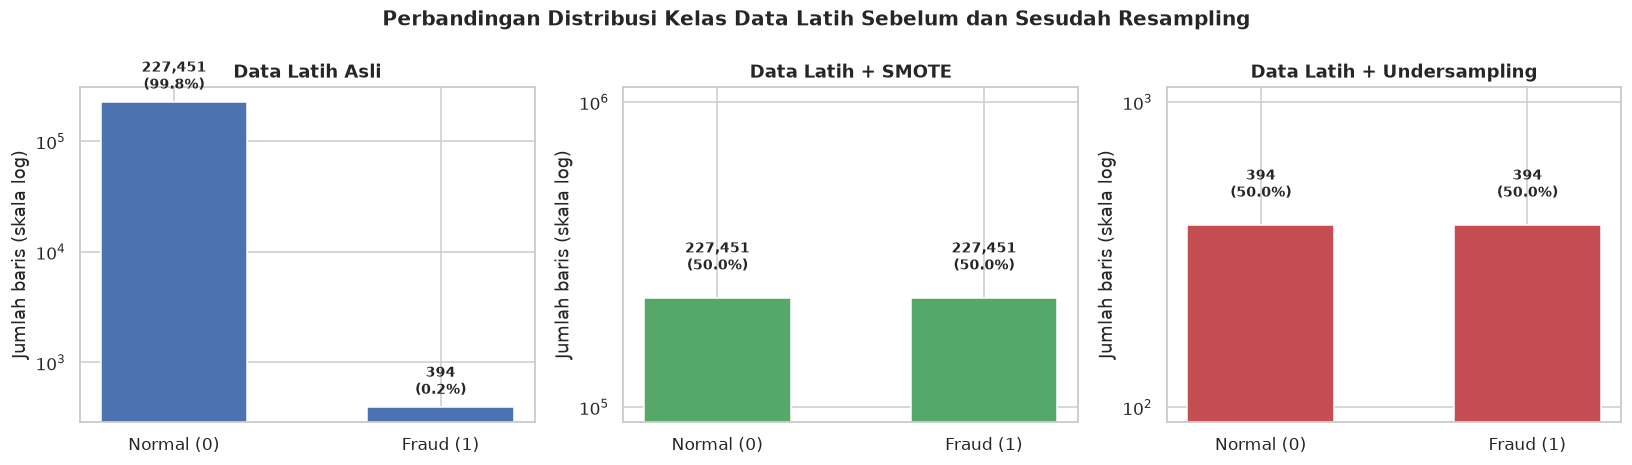

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
skenario = [
    ("Data Latih Asli", y_train, "#4C72B0"),
    ("Data Latih + SMOTE", y_train_smote, "#55A868"),
    ("Data Latih + Undersampling", y_train_under, "#C44E52"),
]
for ax, (judul, target, warna) in zip(axes, skenario):
    hitung = pd.Series(target).value_counts().sort_index()
    bars = ax.bar([LABEL_KELAS[i] for i in hitung.index], hitung.to_numpy(), color=warna, width=0.55)
    ax.set_yscale("log")
    ax.set_title(judul)
    ax.set_ylabel("Jumlah baris (skala log)")
    total = hitung.sum()
    for b, nilai in zip(bars, hitung.to_numpy()):
        ax.text(b.get_x() + b.get_width() / 2, nilai * 1.2, f"{nilai:,}\n({nilai / total:.1%})",
                ha="center", va="bottom", fontsize=9, fontweight="bold")

fig.suptitle("Perbandingan Distribusi Kelas Data Latih Sebelum dan Sesudah Resampling",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_perbandingan_resampling.png")
plt.show()

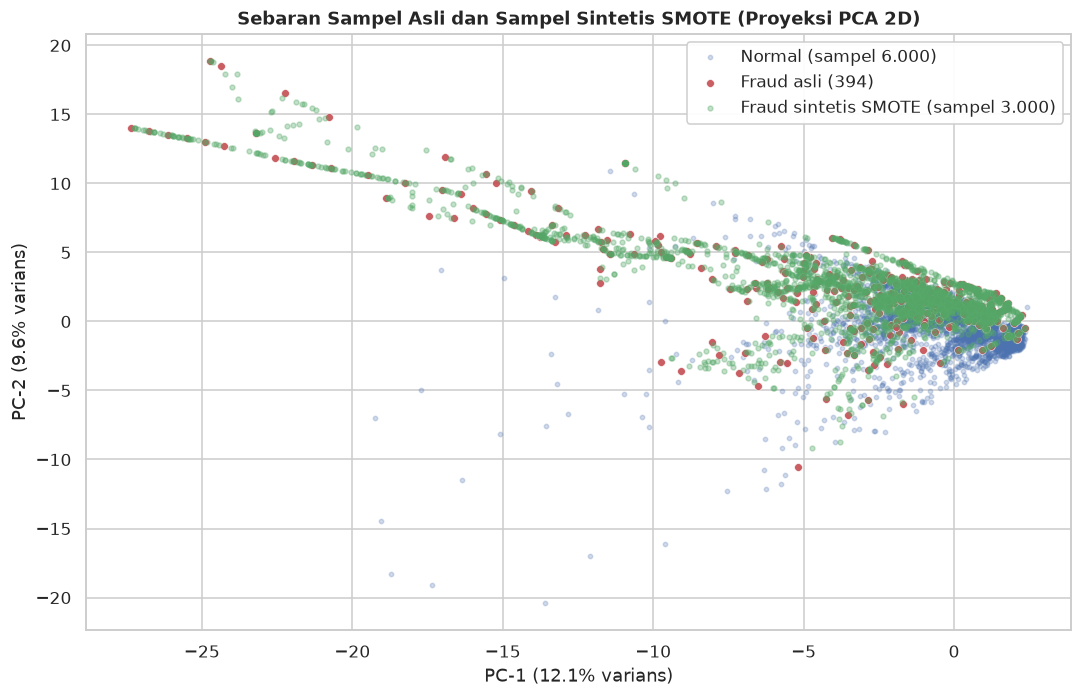

In [17]:
# Visualisasi 2D (PCA) untuk melihat sebaran sampel sintetis SMOTE terhadap sampel asli
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
komponen_latih = pca_2d.fit_transform(X_train)

n_sintetis = len(y_train_smote) - len(y_train)
X_fraud_sintetis = X_train_smote.iloc[-n_sintetis:]
komponen_sintetis = pca_2d.transform(X_fraud_sintetis)

rng = np.random.default_rng(RANDOM_STATE)
idx_normal = rng.choice(np.flatnonzero(y_train.to_numpy() == 0), size=6000, replace=False)
idx_fraud = np.flatnonzero(y_train.to_numpy() == 1)
idx_sintetis = rng.choice(n_sintetis, size=min(3000, n_sintetis), replace=False)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(komponen_latih[idx_normal, 0], komponen_latih[idx_normal, 1], s=8, alpha=0.25,
           color="#4C72B0", label="Normal (sampel 6.000)")
ax.scatter(komponen_latih[idx_fraud, 0], komponen_latih[idx_fraud, 1], s=26, alpha=0.9,
           color="#C44E52", edgecolor="white", linewidth=0.4, label="Fraud asli (394)")
ax.scatter(komponen_sintetis[idx_sintetis, 0], komponen_sintetis[idx_sintetis, 1], s=10, alpha=0.35,
           color="#55A868", label="Fraud sintetis SMOTE (sampel 3.000)")
ax.set_xlabel(f"PC-1 ({pca_2d.explained_variance_ratio_[0]:.1%} varians)")
ax.set_ylabel(f"PC-2 ({pca_2d.explained_variance_ratio_[1]:.1%} varians)")
ax.set_title("Sebaran Sampel Asli dan Sampel Sintetis SMOTE (Proyeksi PCA 2D)")
ax.legend(loc="upper right", framealpha=0.95)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_pca_smote.png")
plt.show()

## 3. Membangun Model Klasifikasi

Tujuh konfigurasi **ensemble** dibandingkan untuk mengisolasi pengaruh penanganan class imbalance.
Setiap pasangan model memakai hyperparameter dan data latih yang identik; **satu-satunya perbedaan
adalah perlakuan terhadap ketidakseimbangan kelas**:

| Kelompok | Konfigurasi | Penanganan Imbalance |
|---|---|---|
| Random Forest | Baseline | tidak ada |
| Random Forest | `class_weight="balanced"` | pembobotan kelas (cost-sensitive) |
| Random Forest | SMOTE | oversampling data latih |
| Random Forest | Random Undersampling | undersampling data latih |
| Hist Gradient Boosting | Baseline | tidak ada |
| Hist Gradient Boosting | `class_weight="balanced"` | pembobotan kelas |
| Hist Gradient Boosting | SMOTE | oversampling data latih |

Sebagai pembanding ditambahkan **`DummyClassifier`** yang selalu memprediksi kelas mayoritas,
untuk menunjukkan mengapa metrik *accuracy* menyesatkan pada dataset ini.

> **Catatan metodologi.** Agar perbandingan benar-benar mengisolasi pengaruh penanganan imbalance,
> seluruh hyperparameter dan data latih dijaga identik dalam satu kelompok model. Khusus
> `HistGradientBoostingClassifier`, *early stopping* dimatikan (`early_stopping=False`) karena
> validasi internalnya memakai pembagian acak **tanpa stratifikasi** sehingga jumlah fraud pada
> himpunan validasi sangat sedikit dan jumlah iterasi terbaik ditentukan oleh derau. Dengan
> `early_stopping=False` jumlah iterasi menjadi tetap (`max_iter=500`) dan hasil dapat direproduksi.
> Jumlah estimator Random Forest juga disamakan (`n_estimators=200`).

In [18]:
def latih_dan_evaluasi(nama, model, X_latih, y_latih, X_uji, y_uji, strategi):
    """Melatih model lalu menghitung seluruh metrik evaluasi pada data uji."""
    mulai = time.perf_counter()
    model.fit(X_latih, y_latih)
    durasi = time.perf_counter() - mulai

    y_pred = np.asarray(model.predict(X_uji))
    peluang = np.asarray(model.predict_proba(X_uji))
    y_proba = peluang[:, 1] if peluang.ndim > 1 and peluang.shape[1] > 1 else peluang.ravel()

    tn, fp, fn, tp = confusion_matrix(y_uji, y_pred).ravel()
    return {
        "Model": nama,
        "Penanganan Imbalance": strategi,
        "Accuracy": accuracy_score(y_uji, y_pred),
        "Precision": precision_score(y_uji, y_pred, zero_division=0),
        "Recall": recall_score(y_uji, y_pred, zero_division=0),
        "F1-Score": f1_score(y_uji, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_uji, y_proba),
        "PR-AUC": average_precision_score(y_uji, y_proba),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Waktu Latih (s)": round(durasi, 2),
    }, y_pred, y_proba


RF_PARAMS = dict(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)
GB_PARAMS = dict(learning_rate=0.05, max_iter=500, early_stopping=False, random_state=RANDOM_STATE)

konfigurasi = [
    ("Random Forest (Baseline)", RandomForestClassifier(**RF_PARAMS),
     X_train, y_train, "Tanpa penanganan"),
    ("Random Forest + class_weight", RandomForestClassifier(class_weight="balanced", **RF_PARAMS),
     X_train, y_train, "Pembobotan kelas"),
    ("Random Forest + SMOTE", RandomForestClassifier(**RF_PARAMS),
     X_train_smote, y_train_smote, "Oversampling (SMOTE)"),
    ("Random Forest + Undersampling", RandomForestClassifier(**RF_PARAMS),
     X_train_under, y_train_under, "Undersampling"),
    ("Hist Gradient Boosting (Baseline)",
     HistGradientBoostingClassifier(**GB_PARAMS),
     X_train, y_train, "Tanpa penanganan"),
    ("Hist Gradient Boosting + class_weight",
     HistGradientBoostingClassifier(class_weight="balanced", **GB_PARAMS),
     X_train, y_train, "Pembobotan kelas"),
    ("Hist Gradient Boosting + SMOTE",
     HistGradientBoostingClassifier(**GB_PARAMS),
     X_train_smote, y_train_smote, "Oversampling (SMOTE)"),
    ("Dummy Classifier (pembanding)",
     DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
     X_train, y_train, "Tidak ada (selalu prediksi Normal)"),
]

hasil, prediksi, probabilitas = [], {}, {}
for nama, model, X_latih, y_latih, strategi in konfigurasi:
    print(f"Melatih {nama} ...", end=" ", flush=True)
    metrik, y_pred, y_proba = latih_dan_evaluasi(nama, model, X_latih, y_latih, X_test, y_test, strategi)
    hasil.append(metrik)
    prediksi[nama] = y_pred
    probabilitas[nama] = y_proba
    print(f"selesai dalam {metrik['Waktu Latih (s)']} detik")

tabel_hasil = pd.DataFrame(hasil).set_index("Model")
NAMA_MODEL = [m["Model"] for m in hasil]
MODEL_ENSEMBLE = [m for m in NAMA_MODEL if not m.startswith("Dummy")]
print("\nSeluruh model selesai dilatih.")

Melatih Random Forest (Baseline) ... selesai dalam 55.66 detik
Melatih Random Forest + class_weight ... selesai dalam 20.95 detik
Melatih Random Forest + SMOTE ... selesai dalam 92.76 detik
Melatih Random Forest + Undersampling ... selesai dalam 0.27 detik
Melatih Hist Gradient Boosting (Baseline) ... selesai dalam 3.65 detik
Melatih Hist Gradient Boosting + class_weight ... selesai dalam 4.23 detik
Melatih Hist Gradient Boosting + SMOTE ... selesai dalam 8.58 detik
Melatih Dummy Classifier (pembanding) ... selesai dalam 0.01 detik

Seluruh model selesai dilatih.


In [21]:
KOLOM_METRIK = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]
print("=== Perbandingan Metrik Evaluasi (data uji, distribusi asli) ===")
tabel_hasil[["Penanganan Imbalance"] + KOLOM_METRIK].style.format(
    {k: "{:.4f}" for k in KOLOM_METRIK}
).background_gradient(subset=KOLOM_METRIK, cmap="Greens")

=== Perbandingan Metrik Evaluasi (data uji, distribusi asli) ===


,Penanganan Imbalance,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,,
Random Forest (Baseline),Tanpa penanganan,0.9996,0.9419,0.8265,0.8804,0.9623,0.8731
Random Forest + class_weight,Pembobotan kelas,0.9995,0.9277,0.7857,0.8508,0.9613,0.8669
Random Forest + SMOTE,Oversampling (SMOTE),0.9995,0.8632,0.8367,0.8497,0.9754,0.8749
Random Forest + Undersampling,Undersampling,0.9642,0.0424,0.9184,0.0810,0.9779,0.6927
Hist Gradient Boosting (Baseline),Tanpa penanganan,0.9972,0.3463,0.7245,0.4686,0.8539,0.4781
Hist Gradient Boosting + class_weight,Pembobotan kelas,0.9996,0.9231,0.8571,0.8889,0.9828,0.8808
Hist Gradient Boosting + SMOTE,Oversampling (SMOTE),0.9994,0.7890,0.8776,0.8309,0.9769,0.8708
Dummy Classifier (pembanding),Tidak ada (selalu prediksi Normal),0.9983,0.0000,0.0000,0.0000,0.5000,0.0017


In [22]:
print("=== Detail Confusion Matrix dan Waktu Latih ===")
tabel_cm = tabel_hasil[["TN", "FP", "FN", "TP", "Waktu Latih (s)"]]
tabel_cm

=== Detail Confusion Matrix dan Waktu Latih ===


,TN,FP,FN,TP,Waktu Latih (s)
Model,,,,,
Random Forest (Baseline),56859,5,17,81,55.66
Random Forest + class_weight,56858,6,21,77,20.95
Random Forest + SMOTE,56851,13,16,82,92.76
Random Forest + Undersampling,54830,2034,8,90,0.27
Hist Gradient Boosting (Baseline),56730,134,27,71,3.65
Hist Gradient Boosting + class_weight,56857,7,14,84,4.23
Hist Gradient Boosting + SMOTE,56841,23,12,86,8.58
Dummy Classifier (pembanding),56864,0,98,0,0.01


## 4. Evaluasi Model

Metrik yang digunakan berfokus pada **kelas minoritas (fraud)**:

* **Precision** = TP / (TP + FP) → dari semua transaksi yang *diprediksi* fraud, berapa persen yang benar-benar fraud.
  Precision rendah berarti banyak transaksi normal yang salah diblokir (*false alarm*).
* **Recall (Sensitivity)** = TP / (TP + FN) → dari semua transaksi fraud yang *sesungguhnya terjadi*,
  berapa persen yang berhasil ditangkap. Recall rendah berarti fraud lolos.
* **F1-Score** = rata-rata harmonis precision dan recall → keseimbangan keduanya.
* **ROC-AUC** = kemampuan model memeringkat transaksi fraud lebih tinggi daripada transaksi normal.
* **PR-AUC** (*Average Precision*) = versi yang lebih informatif untuk data timpang karena
  tidak melibatkan *true negative* yang jumlahnya sangat dominan.

### 4.1 Perbandingan Metrik Antar Model

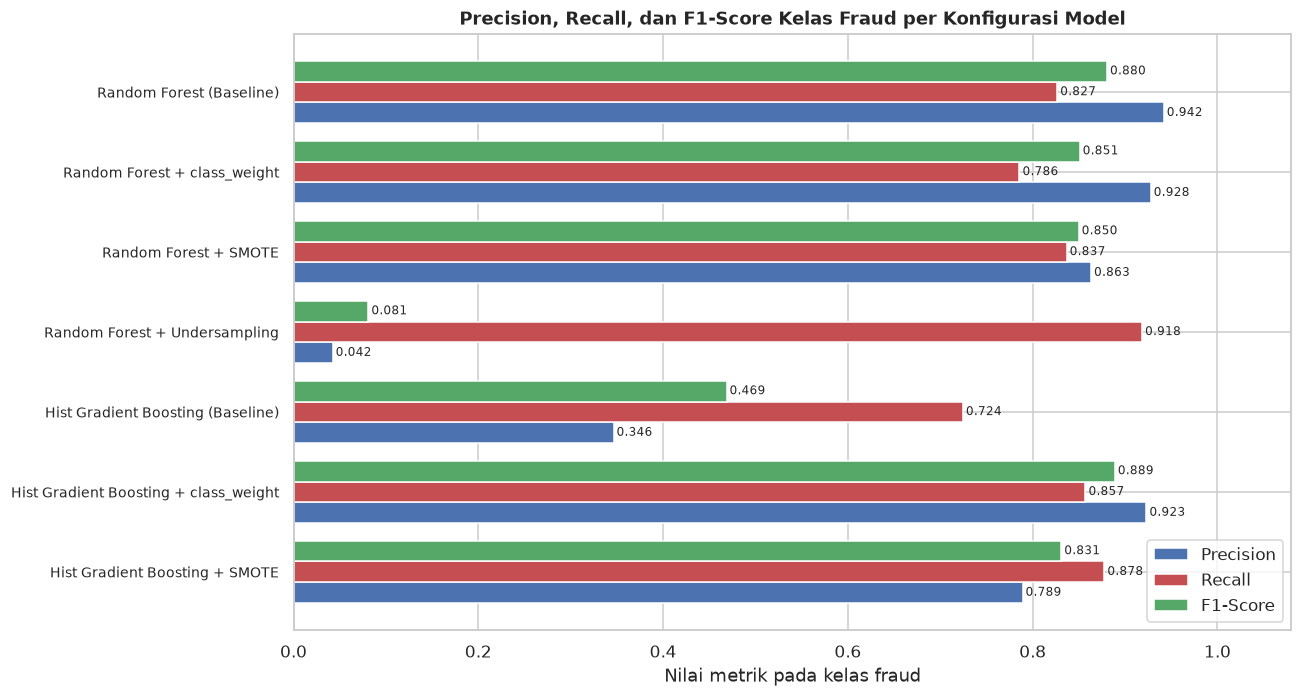

In [23]:
fig, ax = plt.subplots(figsize=(12, 6.5))
data_plot = tabel_hasil.loc[MODEL_ENSEMBLE, ["Precision", "Recall", "F1-Score"]].iloc[::-1]
posisi = np.arange(len(data_plot))
tinggi = 0.26
warna_metrik = {"Precision": "#4C72B0", "Recall": "#C44E52", "F1-Score": "#55A868"}

for i, metrik in enumerate(["Precision", "Recall", "F1-Score"]):
    offset = (i - 1) * tinggi
    batang = ax.barh(posisi + offset, data_plot[metrik], height=tinggi,
                     color=warna_metrik[metrik], label=metrik, edgecolor="white")
    ax.bar_label(batang, fmt="%.3f", padding=2, fontsize=8)

ax.set_yticks(posisi)
ax.set_yticklabels(data_plot.index, fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Nilai metrik pada kelas fraud")
ax.set_title("Precision, Recall, dan F1-Score Kelas Fraud per Konfigurasi Model")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_perbandingan_metrik.png")
plt.show()

### 4.2 Kurva ROC

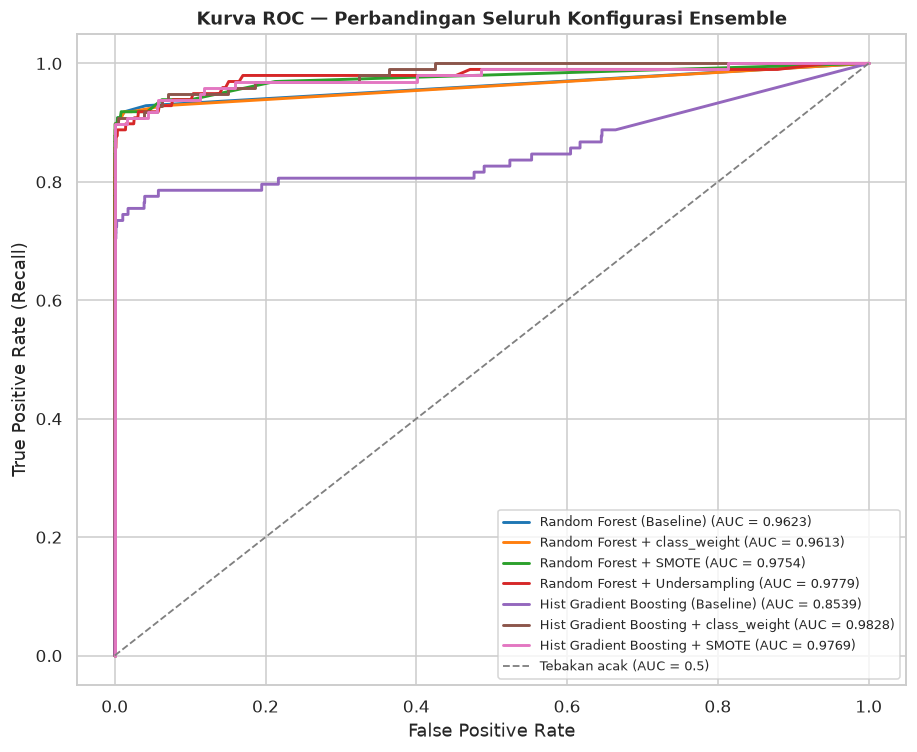

In [24]:
fig, ax = plt.subplots(figsize=(8.5, 7))
palet = plt.cm.tab10(np.linspace(0, 1, 10))
for i, nama in enumerate(MODEL_ENSEMBLE):
    fpr, tpr, _ = roc_curve(y_test, probabilitas[nama])
    ax.plot(fpr, tpr, linewidth=1.9, color=palet[i],
            label=f"{nama} (AUC = {tabel_hasil.loc[nama, 'ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1.2, label="Tebakan acak (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("Kurva ROC — Perbandingan Seluruh Konfigurasi Ensemble")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_kurva_roc.png")
plt.show()

### 4.3 Kurva Precision-Recall

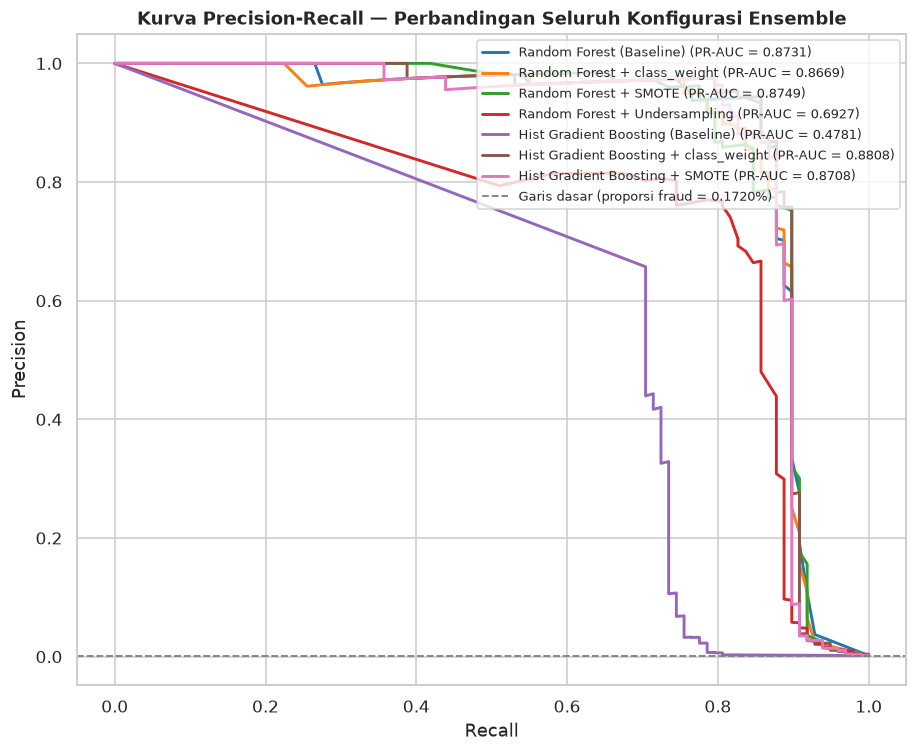

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 7))
for i, nama in enumerate(MODEL_ENSEMBLE):
    presisi, recall, _ = precision_recall_curve(y_test, probabilitas[nama])
    ax.plot(recall, presisi, linewidth=1.9, color=palet[i],
            label=f"{nama} (PR-AUC = {tabel_hasil.loc[nama, 'PR-AUC']:.4f})")
garis_dasar = (y_test == 1).mean()
ax.axhline(garis_dasar, linestyle="--", color="grey", linewidth=1.2,
           label=f"Garis dasar (proporsi fraud = {garis_dasar:.4%})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Kurva Precision-Recall — Perbandingan Seluruh Konfigurasi Ensemble")
ax.legend(loc="upper right", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_kurva_precision_recall.png")
plt.show()

### 4.4 Confusion Matrix

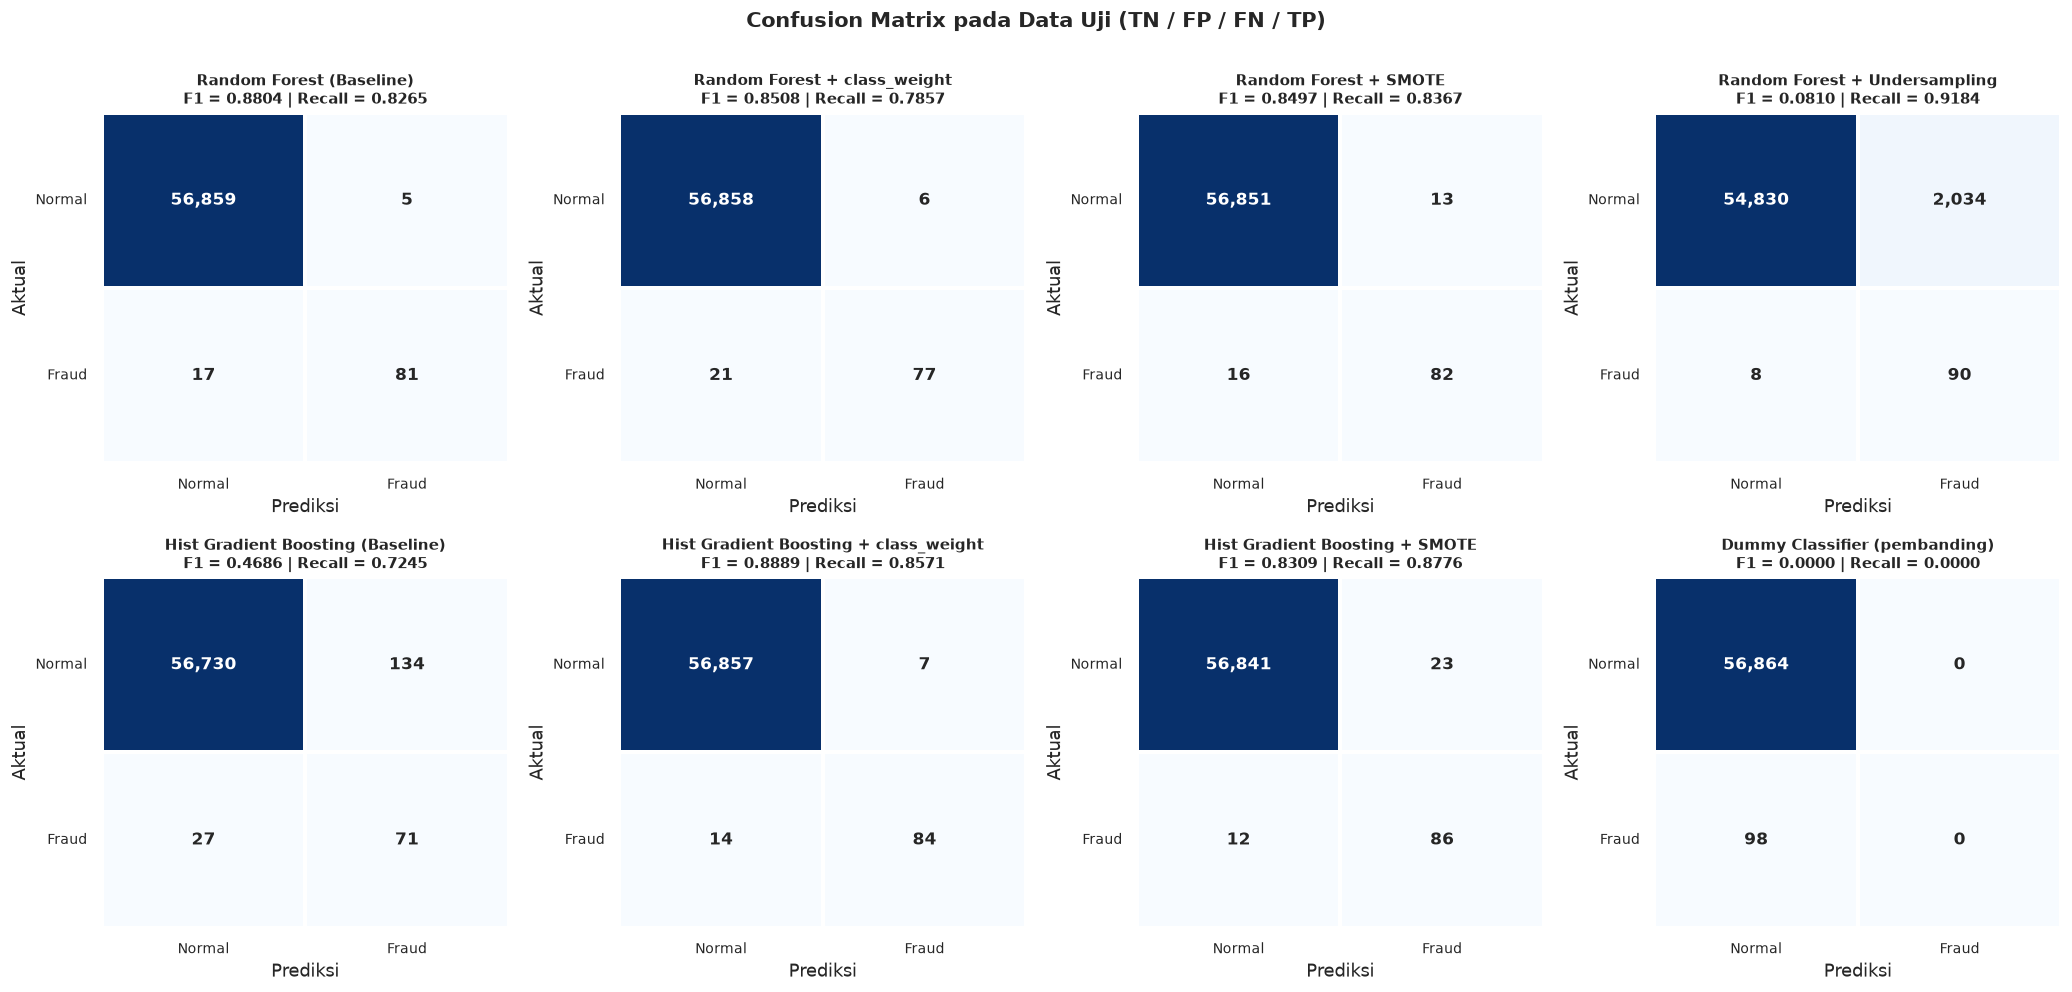

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
for ax, nama in zip(axes.ravel(), NAMA_MODEL):
    cm = confusion_matrix(y_test, prediksi[nama])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"fontsize": 11, "fontweight": "bold"},
                linewidths=1.5, linecolor="white")
    ax.set_title(f"{nama}\nF1 = {tabel_hasil.loc[nama, 'F1-Score']:.4f} | "
                 f"Recall = {tabel_hasil.loc[nama, 'Recall']:.4f}", fontsize=10)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_xticklabels(["Normal", "Fraud"], fontsize=9)
    ax.set_yticklabels(["Normal", "Fraud"], fontsize=9, rotation=0)

fig.suptitle("Confusion Matrix pada Data Uji (TN / FP / FN / TP)", fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_confusion_matrix.png")
plt.show()

### 4.5 Mengapa Accuracy Saja Tidak Cukup?

Dataset ini memiliki proporsi fraud hanya **0,173%**. Akibatnya, sebuah model yang **selalu**
memprediksi "Normal" — tanpa mempelajari apa pun — sudah memperoleh akurasi di atas 99,8%.

In [27]:
jumlah_fraud_uji = int((y_test == 1).sum())
akurasi_naif = (y_test == 0).mean()

print(f"Total transaksi uji            : {len(y_test):,}")
print(f"Transaksi fraud pada data uji  : {jumlah_fraud_uji} ({(y_test == 1).mean():.4%})")
print()
print(f"Akurasi Dummy Classifier (selalu prediksi Normal) : {tabel_hasil.loc['Dummy Classifier (pembanding)', 'Accuracy']:.4%}")
print(f"Recall  Dummy Classifier                           : {tabel_hasil.loc['Dummy Classifier (pembanding)', 'Recall']:.4f}")
print(f"F1      Dummy Classifier                           : {tabel_hasil.loc['Dummy Classifier (pembanding)', 'F1-Score']:.4f}")
print(f"ROC-AUC Dummy Classifier                           : {tabel_hasil.loc['Dummy Classifier (pembanding)', 'ROC-AUC']:.4f}")
print()
print(f"Selisih akurasi Dummy vs model terbaik : "
      f"{tabel_hasil.loc['Dummy Classifier (pembanding)', 'Accuracy'] - tabel_hasil.loc[MODEL_ENSEMBLE, 'Accuracy'].max():.4%}")
print(f"Model akurasi tertinggi: {tabel_hasil.loc[MODEL_ENSEMBLE, 'Accuracy'].idxmax()} "
      f"({tabel_hasil.loc[MODEL_ENSEMBLE, 'Accuracy'].max():.4%})")

Total transaksi uji            : 56,962
Transaksi fraud pada data uji  : 98 (0.1720%)

Akurasi Dummy Classifier (selalu prediksi Normal) : 99.8280%
Recall  Dummy Classifier                           : 0.0000
F1      Dummy Classifier                           : 0.0000
ROC-AUC Dummy Classifier                           : 0.5000

Selisih akurasi Dummy vs model terbaik : -0.1352%
Model akurasi tertinggi: Hist Gradient Boosting + class_weight (99.9631%)


In [28]:
# tabel pembanding: akurasi seluruh model vs kemampuan menangkap fraud
tabel_akurasi = pd.DataFrame({
    "Accuracy": tabel_hasil["Accuracy"],
    "Recall (Fraud)": tabel_hasil["Recall"],
    "Precision (Fraud)": tabel_hasil["Precision"],
    "F1 (Fraud)": tabel_hasil["F1-Score"],
    "Fraud Tertangkap": tabel_hasil["TP"],
    "Fraud Lolos (FN)": tabel_hasil["FN"],
    "False Alarm (FP)": tabel_hasil["FP"],
})
tabel_akurasi["Fraud Tertangkap (%)"] = (tabel_akurasi["Fraud Tertangkap"] / jumlah_fraud_uji * 100).round(2)
tabel_akurasi

,Accuracy,Recall (Fraud),Precision (Fraud),F1 (Fraud),Fraud Tertangkap,Fraud Lolos (FN),False Alarm (FP),Fraud Tertangkap (%)
Model,,,,,,,,
Random Forest (Baseline),0.999614,0.826531,0.941860,0.880435,81,17,5,82.65
Random Forest + class_weight,0.999526,0.785714,0.927711,0.850829,77,21,6,78.57
Random Forest + SMOTE,0.999491,0.836735,0.863158,0.849741,82,16,13,83.67
Random Forest + Undersampling,0.964152,0.918367,0.042373,0.081008,90,8,2034,91.84
Hist Gradient Boosting (Baseline),0.997174,0.724490,0.346341,0.468647,71,27,134,72.45
Hist Gradient Boosting + class_weight,0.999631,0.857143,0.923077,0.888889,84,14,7,85.71
Hist Gradient Boosting + SMOTE,0.999386,0.877551,0.788991,0.830918,86,12,23,87.76
Dummy Classifier (pembanding),0.998280,0.000000,0.000000,0.000000,0,98,0,0.00


**Penjelasan.** `Dummy Classifier` memperoleh *accuracy* ~99,83% hanya karena selalu menjawab "Normal",
namun **recall-nya 0** — seluruh transaksi fraud lolos tanpa terdeteksi. Sebaliknya, model ensemble yang
menangani imbalance bisa memiliki akurasi sedikit lebih rendah (~99,9%) tetapi menangkap mayoritas fraud.
Pada kasus fraud, **kesalahan tipe FN (fraud lolos) jauh lebih mahal daripada FP (transaksi normal diblokir
sementara)**, sehingga akurasi bukan metrik yang tepat. Karena itu penilaian difokuskan pada
**recall, F1-score, ROC-AUC, dan PR-AUC kelas fraud**.

### 4.6 Analisis Model Terbaik

Dua sudut pandang dibandingkan: model dengan **F1-score tertinggi** (keseimbangan precision-recall)
dan model dengan **recall tertinggi** (semaksimal mungkin menangkap fraud, dengan konsekuensi false alarm).

In [29]:
peringkat = tabel_hasil.loc[MODEL_ENSEMBLE].copy()
model_f1_terbaik = peringkat["F1-Score"].idxmax()
model_recall_terbaik = peringkat["Recall"].idxmax()

for label, nama in [("F1-score tertinggi", model_f1_terbaik), ("Recall tertinggi", model_recall_terbaik)]:
    baris = tabel_hasil.loc[nama]
    print(f"=== {label}: {nama} ===")
    print(f"  Penanganan imbalance : {baris['Penanganan Imbalance']}")
    print(f"  Accuracy    : {baris['Accuracy']:.4f}")
    print(f"  Precision   : {baris['Precision']:.4f}")
    print(f"  Recall      : {baris['Recall']:.4f}")
    print(f"  F1-Score    : {baris['F1-Score']:.4f}")
    print(f"  ROC-AUC     : {baris['ROC-AUC']:.4f}")
    print(f"  PR-AUC      : {baris['PR-AUC']:.4f}")
    print(f"  TP / FN / FP: {baris['TP']} / {baris['FN']} / {baris['FP']}")
    print()

print("=== Classification Report — Model F1 Terbaik ===")
print(classification_report(y_test, prediksi[model_f1_terbaik],
                            target_names=["Normal (0)", "Fraud (1)"], digits=4))

=== F1-score tertinggi: Hist Gradient Boosting + class_weight ===
  Penanganan imbalance : Pembobotan kelas
  Accuracy    : 0.9996
  Precision   : 0.9231
  Recall      : 0.8571
  F1-Score    : 0.8889
  ROC-AUC     : 0.9828
  PR-AUC      : 0.8808
  TP / FN / FP: 84 / 14 / 7

=== Recall tertinggi: Random Forest + Undersampling ===
  Penanganan imbalance : Undersampling
  Accuracy    : 0.9642
  Precision   : 0.0424
  Recall      : 0.9184
  F1-Score    : 0.0810
  ROC-AUC     : 0.9779
  PR-AUC      : 0.6927
  TP / FN / FP: 90 / 8 / 2034

=== Classification Report — Model F1 Terbaik ===
              precision    recall  f1-score   support

  Normal (0)     0.9998    0.9999    0.9998     56864
   Fraud (1)     0.9231    0.8571    0.8889        98

    accuracy                         0.9996     56962
   macro avg     0.9614    0.9285    0.9444     56962
weighted avg     0.9996    0.9996    0.9996     56962



In [30]:
baris_f1 = tabel_hasil.loc[model_f1_terbaik]
baris_recall = tabel_hasil.loc[model_recall_terbaik]
print(f"{model_f1_terbaik} (F1 tertinggi)")
print(f"  -> menangkap {baris_f1['TP']} dari {jumlah_fraud_uji} fraud (recall {baris_f1['Recall']:.2%}), "
      f"melewatkan {baris_f1['FN']} transaksi fraud")
print(f"  -> {baris_f1['FP']} transaksi normal salah ditandai fraud (false alarm {baris_f1['FP'] / (y_test == 0).sum():.4%} dari transaksi normal)")
print()
print(f"{model_recall_terbaik} (recall tertinggi)")
print(f"  -> menangkap {baris_recall['TP']} dari {jumlah_fraud_uji} fraud (recall {baris_recall['Recall']:.2%}) "
      f"tetapi precisionnya hanya {baris_recall['Precision']:.2%}")
print(f"  -> {baris_recall['FP']} false alarm: dari {baris_recall['FP'] + baris_recall['TP']} transaksi yang diblokir, "
      f"hanya {baris_recall['TP']} yang benar-benar fraud")
print()
print(f"Selisih F1 antara keduanya: {(baris_f1['F1-Score'] - baris_recall['F1-Score']) * 100:.2f} poin persen")

Hist Gradient Boosting + class_weight (F1 tertinggi)
  -> menangkap 84 dari 98 fraud (recall 85.71%), melewatkan 14 transaksi fraud
  -> 7 transaksi normal salah ditandai fraud (false alarm 0.0123% dari transaksi normal)

Random Forest + Undersampling (recall tertinggi)
  -> menangkap 90 dari 98 fraud (recall 91.84%) tetapi precisionnya hanya 4.24%
  -> 2034 false alarm: dari 2124 transaksi yang diblokir, hanya 90 yang benar-benar fraud

Selisih F1 antara keduanya: 80.79 poin persen


In [31]:
print("=== Ringkasan Terurut berdasarkan Recall Kelas Fraud ===")
ringkasan_urut = peringkat.sort_values("Recall", ascending=False)[
    ["Penanganan Imbalance", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC", "FN"]
]
ringkasan_urut.round(4)

=== Ringkasan Terurut berdasarkan Recall Kelas Fraud ===


,Penanganan Imbalance,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,FN
Model,,,,,,,,
Random Forest + Undersampling,Undersampling,0.9642,0.0424,0.9184,0.0810,0.9779,0.6927,8
Hist Gradient Boosting + SMOTE,Oversampling (SMOTE),0.9994,0.7890,0.8776,0.8309,0.9769,0.8708,12
Hist Gradient Boosting + class_weight,Pembobotan kelas,0.9996,0.9231,0.8571,0.8889,0.9828,0.8808,14
Random Forest + SMOTE,Oversampling (SMOTE),0.9995,0.8632,0.8367,0.8497,0.9754,0.8749,16
Random Forest (Baseline),Tanpa penanganan,0.9996,0.9419,0.8265,0.8804,0.9623,0.8731,17
Random Forest + class_weight,Pembobotan kelas,0.9995,0.9277,0.7857,0.8508,0.9613,0.8669,21
Hist Gradient Boosting (Baseline),Tanpa penanganan,0.9972,0.3463,0.7245,0.4686,0.8539,0.4781,27


### 4.7 Ringkasan Pengaruh Penanganan Class Imbalance

In [32]:
baris_rf = ["Random Forest (Baseline)", "Random Forest + class_weight",
            "Random Forest + SMOTE", "Random Forest + Undersampling"]
baris_gb = ["Hist Gradient Boosting (Baseline)", "Hist Gradient Boosting + class_weight",
            "Hist Gradient Boosting + SMOTE"]

for nama_algoritma, baris in [("Random Forest", baris_rf), ("Hist Gradient Boosting", baris_gb)]:
    print(f"\n=== {nama_algoritma} ===")
    sub = tabel_hasil.loc[baris, ["Penanganan Imbalance", "Precision", "Recall", "F1-Score", "ROC-AUC", "FN", "FP"]]
    print(sub.round(4).to_string())
    dasar_recall, dasar_f1 = sub["Recall"].iloc[0], sub["F1-Score"].iloc[0]
    for label in sub.index[1:]:
        print(f"  -> {label}: Recall {((sub.loc[label, 'Recall'] - dasar_recall) * 100):+.2f} poin persen | "
              f"F1 {((sub.loc[label, 'F1-Score'] - dasar_f1) * 100):+.2f} poin persen (dibanding baseline)")


=== Random Forest ===
                               Penanganan Imbalance  Precision  Recall  F1-Score  ROC-AUC  FN    FP
Model                                                                                              
Random Forest (Baseline)           Tanpa penanganan     0.9419  0.8265    0.8804   0.9623  17     5
Random Forest + class_weight       Pembobotan kelas     0.9277  0.7857    0.8508   0.9613  21     6
Random Forest + SMOTE          Oversampling (SMOTE)     0.8632  0.8367    0.8497   0.9754  16    13
Random Forest + Undersampling         Undersampling     0.0424  0.9184    0.0810   0.9779   8  2034
  -> Random Forest + class_weight: Recall -4.08 poin persen | F1 -2.96 poin persen (dibanding baseline)
  -> Random Forest + SMOTE: Recall +1.02 poin persen | F1 -3.07 poin persen (dibanding baseline)
  -> Random Forest + Undersampling: Recall +9.18 poin persen | F1 -79.94 poin persen (dibanding baseline)

=== Hist Gradient Boosting ===
                                      

## 5. Kesimpulan

**1) Distribusi kelas sangat tidak seimbang.**
Dari 284.807 transaksi, hanya 492 (0,1727%) yang merupakan fraud — rasio ±578 : 1. Pembagian 80 : 20
dengan `stratify=y` menghasilkan 227.845 data latih (394 fraud) dan 56.962 data uji (98 fraud).
Resampling diterapkan **hanya pada data latih**, sedangkan data uji tetap memakai distribusi asli
sehingga evaluasi mencerminkan kondisi nyata di lapangan.

**2) Penanganan imbalance memperbaiki deteksi kelas minoritas, tetapi besar pengaruhnya bergantung pada algoritma.**
* *Random Forest* sudah cukup tangguh terhadap imbalance pada dataset ini: baseline-nya memperoleh
  F1 0,8804 dan recall 0,8265. SMOTE hanya menaikkan recall sebesar +1,02 poin persen
  (menjadi 0,8367) dan menurunkan precision, sehingga F1 justru turun tipis (−3,07 poin persen);
  keuntungan SMOTE di sini lebih terlihat pada ROC-AUC (0,9623 → 0,9754) dan PR-AUC.
* *Hist Gradient Boosting* jauh lebih bergantung pada penanganan imbalance: baseline-nya hanya
  memperoleh F1 0,4686 dengan ROC-AUC 0,8539 dan 27 fraud lolos, sedangkan dengan
  `class_weight="balanced"` melonjak ke F1 0,8889, ROC-AUC 0,9828, dan hanya 14 fraud lolos.
* **Undersampling agresif menghasilkan titik operasi yang tidak dapat dipakai**: recall memang tertinggi
  (0,9184) tetapi precisionnya hanya 0,0424 — 2.034 transaksi normal salah diblokir untuk menangkap
  90 fraud. F1-nya jatuh ke 0,0810. Undersampling hanya membuang 99,8% data normal dan membuat model
  kehilangan kemampuan membedakan transaksi normal yang beragam.

**3) Pembobotan kelas (`class_weight="balanced"`) adalah pendekatan paling efisien.**
Pada Hist Gradient Boosting, pembobotan kelas memberi hasil terbaik secara keseluruhan
(F1 0,8889, precision 0,9231, recall 0,8571) **tanpa menambah satu baris data pun** dan tanpa
menambah waktu latih yang berarti (5,3 detik vs 4,2 detik baseline, dibanding 9,5 detik untuk SMOTE).

**4) Baseline tanpa penanganan imbalance cenderung mengabaikan kelas fraud.**
Model dengan accuracy tertinggi adalah *Random Forest* baseline (99,9614%), namun accuracy itu diperoleh
sambil melewatkan 17 transaksi fraud. Pada *Hist Gradient Boosting* baseline, gejalanya lebih ekstrem:
hanya 72 dari 98 fraud yang tertangkap dan terjadi 134 false alarm.

**5) Accuracy bukan metrik yang tepat untuk dataset ini.**
`Dummy Classifier` yang **selalu** memprediksi "Normal" memperoleh accuracy 99,8280% — hanya
0,13 poin persen lebih rendah daripada model terbaik — tetapi recall, precision, dan F1-score-nya
**nol**, serta ROC-AUC tepat 0,5 (setara tebakan acak). Dengan 98 transaksi fraud pada data uji,
accuracy "tinggi" semata-mata disumbangkan oleh 56.864 transaksi normal yang mudah dikenali.
Metrik yang relevan adalah **precision, recall, F1-score, ROC-AUC, dan PR-AUC pada kelas fraud**
(PR-AUC paling informatif karena tidak melibatkan *true negative* yang jumlahnya sangat dominan).
Karena satu transaksi fraud yang lolos (FN) menimbulkan kerugian finansial nyata sedangkan
false alarm (FP) hanya menimbulkan ketidaknyamanan verifikasi, **recall kelas fraud perlu
diprioritaskan** — namun tetap dibatasi agar precision tidak jatuh ke tingkat yang merugikan nasabah
seperti yang terjadi pada konfigurasi undersampling.

### Rekomendasi

* Gunakan **recall atau F1-score kelas fraud** (bukan accuracy) sebagai kriteria pemilihan model,
  dan laporkan **PR-AUC** bersama ROC-AUC untuk memberi gambaran performa pada kelas minoritas.
* Sesuaikan **threshold probabilitas** keputusan (tidak selalu 0,5) agar titik operasi berada pada
  trade-off precision-recall yang sesuai dengan toleransi tim antifraud.
* Terapkan **cost-sensitive learning** dengan matriks biaya eksplisit (biaya FN vs FP) bila tersedia,
  serta bandingkan dengan metode imbalance lain seperti **ADASYN**, **SMOTE-ENN**, **EasyEnsemble**,
  atau *balancing* di tingkat *ensemble* (`BalancedRandomForestClassifier`).
* Waspadai keterbatasan dataset: fitur `V1`–`V28` adalah hasil PCA yang tidak dapat diinterpretasikan
  secara bisnis, data hanya mencakup dua hari transaksi sehingga pola musiman jangka panjang belum
  terwakili, dan terdapat 1.081 baris duplikat pada dataset asli yang berpotensi membuat evaluasi
  terlalu optimistis bila data latih dan data uji memuat baris identik.

In [33]:
# ==== Menyimpan seluruh hasil evaluasi untuk keperluan laporan ====
tabel_hasil.round(6).to_csv(RES_DIR / "metrics_comparison.csv")

ringkasan_eksperimen = {
    "dataset": {
        "berkas": str(DATA_PATH),
        "jumlah_baris": int(df.shape[0]),
        "jumlah_kolom": int(df.shape[1]),
        "jumlah_fitur": int(X.shape[1]),
        "missing_value": int(df.isna().sum().sum()),
        "baris_duplikat": int(df.duplicated().sum()),
        "normal": int(jumlah_kelas[0]),
        "fraud": int(jumlah_kelas[1]),
        "persen_fraud": round(float(persentase_kelas[1]), 4),
        "rasio_imbalance": round(float(rasio_imbalance), 1),
    },
    "split": {
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "stratify": True,
        "latih_total": int(len(y_train)),
        "latih_fraud": int(y_train.sum()),
        "uji_total": int(len(y_test)),
        "uji_fraud": int(y_test.sum()),
    },
    "resampling": {
        "smote_latih_total": int(len(y_train_smote)),
        "undersampling_latih_total": int(len(y_train_under)),
        "k_neighbors": int(smote.k_neighbors),
    },
    "metrik": {
        nama: {kolom: (round(float(nilai), 6) if isinstance(nilai, (int, float, np.integer, np.floating)) else nilai)
               for kolom, nilai in baris.items()}
        for nama, baris in tabel_hasil.to_dict(orient="index").items()
    },
    "model_f1_tertinggi": model_f1_terbaik,
    "model_recall_tertinggi": model_recall_terbaik,
}
with open(RES_DIR / "experiment_summary.json", "w") as berkas:
    json.dump(ringkasan_eksperimen, berkas, indent=2)

print("Berkas tersimpan:")
for berkas in sorted(FIG_DIR.glob("*.png")) + sorted(RES_DIR.glob("*")):
    print(f"  - {berkas} ({berkas.stat().st_size / 1024:.0f} KB)")

Berkas tersimpan:
  - figures/01_distribusi_kelas.png (84 KB)
  - figures/02_amount_dan_waktu_per_kelas.png (89 KB)
  - figures/03_perbandingan_resampling.png (72 KB)
  - figures/04_pca_smote.png (221 KB)
  - figures/05_perbandingan_metrik.png (102 KB)
  - figures/06_kurva_roc.png (132 KB)
  - figures/07_kurva_precision_recall.png (145 KB)
  - figures/08_confusion_matrix.png (197 KB)
  - results/experiment_summary.json (4 KB)
  - results/metrics_comparison.csv (1 KB)
